In [1]:
import glob
import numpy as np
import matplotlib.pyplot as plt
import dbetto
import lh5
import pandas as pd
import pygeomhades
import pygeomtools
import yaml
from pygeomtools import write_pygeom
import pyg4ometry as pg4
from pyg4ometry import gdml
from pathlib import Path
from copy import deepcopy
from matplotlib.colors import LogNorm

from scipy.optimize import least_squares
from scipy.special import erf, erfc, xlogy
from scipy.stats import exponnorm

%matplotlib inline


In [2]:
import reboost
from reboost import hpge
from reboost.hpge import surface, psd
from reboost.shape import group
from reboost.math import functions
from reboost.math.stats import gaussian_sample
from reboost.utils import get_remage_detector_uids





In [3]:
from remage import remage_run



# functions

In [4]:
def find_matching_background_runs(db, detector, measure, campaign="c1"):
    configuration = db.hardware.configuration[detector][campaign]

    physics_runs = configuration[measure]
    background_runs = configuration["bkg"]

    matches = {}

    for run, data in sorted(physics_runs.items()):
        if not run.startswith("run"):
            continue

        card = data["daq_settings"]["flashcam"]["card_interface"]

        matching_bkg = [
            bkg_run
            for bkg_run, bkg_data in sorted(background_runs.items())
            if bkg_run.startswith("run")
            and bkg_data["daq_settings"]["flashcam"]["card_interface"] == card
        ]

        matches[run] = {
            "card_interface": card,
            "background_runs": matching_bkg,
        }

    return matches

In [5]:

def gaussian_bin_counts(edges, area, mu, sigma):
    z = (edges - mu) / (np.sqrt(2) * sigma)
    return area * 0.5 * np.diff(erf(z))


def left_tail_bin_counts(edges, area, mu, sigma, tau):
    cdf = exponnorm.sf(
        mu - edges,
        tau / sigma,
        loc=0,
        scale=sigma,
    )

    return area * np.maximum(np.diff(cdf), 0)


def step_primitive(x, mu, sigma):
    u = (x - mu) / (np.sqrt(2) * sigma)

    return 0.5 * (
        (x - mu) * erfc(u)
        - sigma * np.sqrt(2 / np.pi) * np.exp(-u**2)
    )


def am60_components(edges, parameters):
    (
        area, mu, sigma,
        tail_area, tau,
        background, step,
    ) = parameters

    peak = gaussian_bin_counts(edges, area, mu, sigma)
    tail = left_tail_bin_counts(
        edges, tail_area, mu, sigma, tau
    )

    continuum = (
        background * np.diff(edges)
        + step * np.diff(
            step_primitive(edges, mu, sigma)
        )
    )

    return {
        "gaussian": peak,
        "tail": tail,
        "continuum": continuum,
        "total": peak + tail + continuum,
    }


def am60_density(x, parameters):
    (
        area, mu, sigma,
        tail_area, tau,
        background, step,
    ) = parameters

    peak = (
        area / (np.sqrt(2 * np.pi) * sigma)
        * np.exp(-0.5 * ((x - mu) / sigma)**2)
    )

    tail = tail_area * exponnorm.pdf(
        mu - x,
        tau / sigma,
        loc=0,
        scale=sigma,
    )

    continuum = (
        background
        + step * 0.5 * erfc(
            (x - mu) / (np.sqrt(2) * sigma)
        )
    )

    return {
        "gaussian": peak,
        "tail": tail,
        "continuum": continuum,
        "total": peak + tail + continuum,
    }


def poisson_residuals(parameters, edges, counts):
    expected = np.maximum(
        am60_components(edges, parameters)["total"],
        1e-12,
    )

    deviance = 2 * (
        expected - counts
        + xlogy(counts, counts / expected)
    )

    return (
        np.sign(expected - counts)
        * np.sqrt(np.maximum(deviance, 0))
    )



In [6]:


def am100_components(edges, parameters):
    (
        N1, mu1,
        N2, mu2,
        N3, mu3,
        sigma,
        S1, S2,
        B,
    ) = parameters

    edges = np.asarray(edges, dtype=float)
    widths = np.diff(edges)

    def gaussian_counts(N, mu):
        return N * np.diff(ndtr((edges - mu) / sigma))

    def step_counts(S, mu):
        # Densità dello step: S * Phi((mu - E) / sigma)
        # Primitiva rispetto all'energia.
        z = (mu - edges) / sigma
        phi = np.exp(-0.5 * z**2) / np.sqrt(2 * np.pi)

        primitive = (
            (edges - mu) * ndtr(z)
            - sigma * phi
        )

        return S * np.maximum(np.diff(primitive), 0.0)

    g1 = gaussian_counts(N1, mu1)
    g2 = gaussian_counts(N2, mu2)
    g3 = gaussian_counts(N3, mu3)

    step1 = step_counts(S1, mu1)
    step2 = step_counts(S2, mu3)

    background = B * widths

    return {
        "gaussian_99": g1,
        "gaussian_101": g2,
        "gaussian_103": g3,
        "step_99": step1,
        "step_103": step2,
        "background": background,
        "total": g1 + g2 + g3 + step1 + step2 + background,
    }


def poisson_residuals_am100(parameters, edges, y):
    expected = am100_components(edges, parameters)["total"]
    expected = np.maximum(expected, np.finfo(float).tiny)

    # Residui della devianza di Poisson, inclusi i bin vuoti.
    deviance = expected - y
    positive = y > 0

    deviance[positive] += y[positive] * (
        np.log(y[positive]) - np.log(expected[positive])
    )

    return np.sign(y - expected) * np.sqrt(
        2.0 * np.maximum(deviance, 0.0)
    )


def fit_am_100(counts, bins, fit_range=(96.0, 106.0)):
    counts = np.asarray(counts, dtype=float)
    bins = np.asarray(bins, dtype=float)

    if counts.ndim != 1 or bins.ndim != 1:
        raise ValueError("counts e bins devono essere 1D.")

    if counts.size == 0 or bins.size != counts.size + 1:
        raise ValueError("Dimensioni istogramma incompatibili.")

    if not np.isfinite(counts).all() or np.any(counts < 0):
        raise ValueError("Conteggi non validi.")

    if not np.isfinite(bins).all() or np.any(np.diff(bins) <= 0):
        raise ValueError("Bordi non validi.")

    xmin, xmax = fit_range

    if not np.isfinite([xmin, xmax]).all() or xmin >= xmax:
        raise ValueError("Finestra di fit non valida.")

    indices = np.flatnonzero(
        (bins[:-1] >= xmin)
        & (bins[1:] <= xmax)
    )

    # 3 aree, 3 centroidi, 1 sigma, 2 step, 1 fondo.
    n_parameters = 10

    if indices.size <= n_parameters:
        raise ValueError("Troppi pochi bin nella finestra di fit.")

    first = indices[0]
    last = indices[-1] + 1

    edges = bins[first:last + 1]
    y = counts[first:last]

    if y.sum() <= 0:
        raise ValueError("Nessun conteggio nella finestra di fit.")

    if edges[0] >= 99.0 or edges[-1] <= 103.0:
        raise ValueError("La finestra deve includere tutti e tre i picchi.")

    widths = np.diff(edges)
    centers = (edges[:-1] + edges[1:]) / 2
    density = y / widths

    background = max(
        float(np.percentile(density, 10)),
        1e-3,
    )

    sigma_guess = 0.4

    def area_guess(mu):
        height = max(
            float(density[np.argmin(np.abs(centers - mu))])
            - background,
            1.0,
        )
        return height * np.sqrt(2 * np.pi) * sigma_guess

    # Ordine: N1, mu1, N2, mu2, N3, mu3, sigma, S1, S2, B.
    p0 = [
        area_guess(99.0), 99.0,
        area_guess(101.1), 101.1,
        area_guess(103.0), 103.0,
        sigma_guess,
        background * 0.5,
        background * 0.5,
        background,
    ]

    lower = [
        0.0, 98.5,
        0.0, 100.6,
        0.0, 102.5,
        0.05,
        0.0, 0.0,
        0.0,
    ]

    upper = [
        np.inf, 99.5,
        np.inf, 101.6,
        np.inf, 103.5,
        1.2,
        np.inf, np.inf,
        np.inf,
    ]

    fit = least_squares(
        poisson_residuals_am100,
        p0,
        bounds=(lower, upper),
        args=(edges, y),
        x_scale="jac",
        max_nfev=20000,
    )

    if not fit.success:
        raise RuntimeError(f"Fit fallito: {fit.message}")

    rank = np.linalg.matrix_rank(fit.jac)
    full_rank = rank == n_parameters

    covariance = (
        np.linalg.pinv(fit.jac.T @ fit.jac)
        if full_rank
        else np.full((n_parameters, n_parameters), np.nan)
    )

    errors = np.sqrt(
        np.maximum(np.diag(covariance), 0.0)
    )

    peak_indices = [0, 2, 4]
    areas = fit.x[peak_indices].copy()

    if not np.isfinite(areas).all() or np.any(areas <= 0):
        raise ValueError("Aree dei picchi non valide.")

    return {
        "parameter_names": [
            "N1", "mu1",
            "N2", "mu2",
            "N3", "mu3",
            "sigma",
            "S1", "S2",
            "B",
        ],
        "parameters": fit.x,
        "errors": errors,
        "covariance": covariance,
        "area_peak": areas,
        "area_peak_errors": errors[peak_indices],
        "mu": fit.x[[1, 3, 5]],
        "mu_errors": errors[[1, 3, 5]],
        "fwhm": 2.35482 * fit.x[6],
        "fwhm_error": 2.35482 * errors[6],
        "edges": edges,
        "counts": y,
        "components": am100_components(edges, fit.x),
        "residuals": fit.fun,
        "deviance": float(np.sum(fit.fun**2)),
        "ndof": y.size - n_parameters,
        "full_rank": full_rank,
        "at_bounds": bool(np.any(fit.active_mask != 0)),
        "active_mask": fit.active_mask,
        "nfev": fit.nfev,
        "message": fit.message,
    }

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ndtr


def am100_density(x, parameters):
    (
        N1, mu1,
        N2, mu2,
        N3, mu3,
        sigma,
        S1, S2,
        B,
    ) = parameters

    x = np.asarray(x, dtype=float)

    def gaussian(N, mu):
        return (
            N / (np.sqrt(2 * np.pi) * sigma)
            * np.exp(-0.5 * ((x - mu) / sigma)**2)
        )

    g1 = gaussian(N1, mu1)
    g2 = gaussian(N2, mu2)
    g3 = gaussian(N3, mu3)

    step1 = S1 * ndtr((mu1 - x) / sigma)
    step2 = S2 * ndtr((mu3 - x) / sigma)
    background = np.full_like(x, B)

    return {
        "gaussian_99": g1,
        "gaussian_101": g2,
        "gaussian_103": g3,
        "step_99": step1,
        "step_103": step2,
        "background": background,
        "total": g1 + g2 + g3 + step1 + step2 + background,
    }


# ============================================================
# FIT FIGURE: EXACTLY (5, 3)
# ============================================================

def plot_am100_fit(result, detector, run, meta, dpi=300):
    fig, (ax, ax_res) = plt.subplots(
        2, 1,
        figsize=(5, 3),
        sharex=True,
        height_ratios=[3, 1],
        layout="constrained",
        dpi=dpi,
    )

    edges = result["edges"]
    centers = (edges[:-1] + edges[1:]) / 2
    widths = np.diff(edges)
    width = widths[0]

    if not np.allclose(widths, width):
        plt.close(fig)
        raise ValueError("Questo plot richiede bin di larghezza uniforme.")

    x = np.linspace(edges[0], edges[-1], 3000)
    smooth = am100_density(x, result["parameters"])

    ax.stairs(
        result["counts"],
        edges,
        color="navy",
        linewidth=0.8,
        label="Data",
    )

    for key, label, color, linestyle in [
        ("total", "Total", "darkorange", "-"),
        ("gaussian_99", "Gaussian 99 keV", "crimson", "--"),
        ("gaussian_101", "Gaussian 101.1 keV", "deepskyblue", "--"),
        ("gaussian_103", "Gaussian 103 keV", "green", "--"),
        ("step_99", "Step 99 keV", "purple", "--"),
        ("step_103", "Step 103 keV", "brown", "--"),
        ("background", "Background", "gray", "--"),
    ]:
        curve = smooth[key] * width

        ax.plot(
            x,
            np.where(curve > 0, curve, np.nan),
            color=color,
            linestyle=linestyle,
            linewidth=0.9,
            label=label,
        )

    ax.set_yscale("log")

    positive = result["counts"][result["counts"] > 0]
    ymax = max(
        result["counts"].max(),
        smooth["total"].max() * width,
    )

    #ax.set_ylim(
    #    max(0.1, min(100.0, positive.min() * 0.5)),
   #     ymax * 2,
   # )

    ax.set_ylim(
        0.01, 2e3
    )

    p = result["parameters"]
    errors = result["errors"]

    text = (
        rf"$A_1={p[0]:.0f}\pm{errors[0]:.0f}$ counts" "\n"
        rf"$\mu_1={p[1]:.4f}\pm{errors[1]:.4f}$ keV" "\n"
        rf"$A_2={p[2]:.0f}\pm{errors[2]:.0f}$ counts" "\n"
        rf"$\mu_2={p[3]:.4f}\pm{errors[3]:.4f}$ keV" "\n"
        rf"$A_3={p[4]:.0f}\pm{errors[4]:.0f}$ counts" "\n"
        rf"$\mu_3={p[5]:.4f}\pm{errors[5]:.4f}$ keV" "\n"
        rf"$\sigma={p[6]:.4f}\pm{errors[6]:.4f}$ keV" "\n"
        rf"$S_1={p[7]:.1f}\pm{errors[7]:.1f}$ counts/keV" "\n"
        rf"$S_2={p[8]:.1f}\pm{errors[8]:.1f}$ counts/keV" "\n"
        rf"$B={p[9]:.1f}\pm{errors[9]:.1f}$ counts/keV" "\n"
        f"FWHM={result['fwhm']:.4f}"
        f" ± {result['fwhm_error']:.4f} keV\n"
        f"D/ndof={result['deviance']:.1f}/{result['ndof']}"
    )

    ax.text(
        0.98, 0.97,
        text,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=5,
        color="navy",
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.85,
            "pad": 2,
        },
    )

    pos = meta["source_position"]

    ax.set_title(
        f"{detector}/{run} | "
        f"r={float(pos['r_in_mm']):g}, "
        f"z={float(pos['z_in_mm']):g} mm, "
        f"φ={float(pos['phi_in_deg']):g}° | "
        f"t={float(meta['run_live_time_in_s']) / 3600:g} h",
        fontsize=7,
    )

    ax.set_ylabel(f"Counts / {width:g} keV", fontsize=7)
    ax.legend(fontsize=5.5, loc="upper left")

    ax_res.axhline(
        0,
        color="gray",
        linestyle="--",
        linewidth=0.6,
    )

    ax_res.plot(
        centers,
        result["residuals"],
        ".",
        color="navy",
        markersize=2,
    )

    ax_res.set_ylabel("Deviance\nresidual", fontsize=6)
    ax_res.set_xlabel("Energy (keV)", fontsize=7)
    ax_res.set_xlim(edges[0], edges[-1])

    for axis in (ax, ax_res):
        axis.tick_params(labelsize=6)

    return fig



In [7]:

def am60_components(edges, parameters):
    area, mu, sigma, tail_area, tau, S = parameters

    edges = np.asarray(edges, dtype=float)

    gaussian = area * np.maximum(
        np.diff(ndtr((edges - mu) / sigma)),
        0.0,
    )

    distribution = exponnorm(
        tau / sigma,
        loc=mu,
        scale=sigma,
    )

    cdf = distribution.cdf(edges)
    sf = distribution.sf(edges)

    probability = np.where(
        cdf[:-1] > 0.5,
        sf[:-1] - sf[1:],
        cdf[1:] - cdf[:-1],
    )

    tail = tail_area * np.maximum(probability, 0.0)

    z = (mu - edges) / sigma
    phi = np.exp(-0.5 * z**2) / np.sqrt(2 * np.pi)

    primitive = (
        (edges - mu) * ndtr(z)
        - sigma * phi
    )

    step = S * np.maximum(
        np.diff(primitive), 0.0
    )

    return {
        "gaussian": gaussian,
        "tail": tail,
        "step": step,
        "total": gaussian + tail + step,
    }


def am60_density(x, parameters):
    area, mu, sigma, tail_area, tau, S = parameters

    x = np.asarray(x, dtype=float)

    gaussian = (
        area / (np.sqrt(2 * np.pi) * sigma)
        * np.exp(-0.5 * ((x - mu) / sigma)**2)
    )

    tail = tail_area * exponnorm.pdf(
        x,
        tau / sigma,
        loc=mu,
        scale=sigma,
    )

    step = S * ndtr((mu - x) / sigma)

    return {
        "gaussian": gaussian,
        "tail": tail,
        "step": step,
        "total": gaussian + tail + step,
    }
    
def am60_density(x, parameters):
    area, mu, sigma, tail_area, tau, S = parameters

    x = np.asarray(x, dtype=float)

    gaussian = (
        area / (np.sqrt(2 * np.pi) * sigma)
        * np.exp(-0.5 * ((x - mu) / sigma)**2)
    )

    tail = tail_area * exponnorm.pdf(
        x,
        tau / sigma,
        loc=mu,
        scale=sigma,
    )

    step = S * ndtr((mu - x) / sigma)

    return {
        "gaussian": gaussian,
        "tail": tail,
        "step": step,
        "total": gaussian + tail + step,
    }


# ============================================================
# POISSON DEVIANCE RESIDUALS
# ============================================================

def poisson_residuals(parameters, edges, counts):
    expected = np.maximum(
        am60_components(edges, parameters)["total"],
        np.finfo(float).tiny,
    )

    half_deviance = expected.copy()
    positive = counts > 0

    observed = counts[positive]
    predicted = expected[positive]

    delta = (predicted - observed) / observed

    near = np.abs(delta) < 0.01
    terms = np.empty_like(delta)

    # Stable expansion near predicted == observed.
    d = delta[near]

    terms[near] = d**2 * (
        0.5 - d / 3 + d**2 / 4
        - d**3 / 5 + d**4 / 6
    )

    terms[~near] = (
        delta[~near]
        + np.log(observed[~near])
        - np.log(predicted[~near])
    )

    half_deviance[positive] = observed * terms

    # Positive residual: data exceed the model.
    return np.sign(counts - expected) * np.sqrt(
        2.0 * np.maximum(half_deviance, 0.0)
    )


# ============================================================
# FIT CALIBRATED RAW COUNTS
# ============================================================

def fit_am60(counts, bins, fit_range=(57, 70)):
    counts = np.asarray(counts, dtype=float)
    bins = np.asarray(bins, dtype=float)

    if counts.ndim != 1 or bins.ndim != 1:
        raise ValueError("counts e bins devono essere 1D.")

    if counts.size == 0 or bins.size != counts.size + 1:
        raise ValueError("Dimensioni istogramma incompatibili.")

    if not np.isfinite(counts).all() or np.any(counts < 0):
        raise ValueError("Conteggi non validi.")

    if (
        not np.isfinite(bins).all()
        or np.any(np.diff(bins) <= 0)
    ):
        raise ValueError("Bordi non validi.")

    xmin, xmax = fit_range

    if not np.isfinite([xmin, xmax]).all() or xmin >= xmax:
        raise ValueError("Finestra di fit non valida.")

    indices = np.flatnonzero(
        (bins[:-1] >= xmin)
        & (bins[1:] <= xmax)
    )

    n_parameters = len(PARAMETER_NAMES)

    if indices.size <= n_parameters:
        raise ValueError(
            "Troppi pochi bin per un fit con 6 parametri."
        )

    first = indices[0]
    last = indices[-1] + 1

    edges = bins[first:last + 1]
    y = counts[first:last]

    if y.sum() <= 0:
        raise ValueError(
            "Nessun conteggio nella finestra di fit."
        )

    if not (edges[0] < 59.54 < edges[-1]):
        raise ValueError(
            "La finestra deve includere il picco a 59.54 keV."
        )

    centers = (edges[:-1] + edges[1:]) / 2
    density = y / np.diff(edges)

    mu_guess = 59.54
    sigma_guess = 0.3

    # Estimate the step plateau below the peak.
    low_energy = centers < 58.5

    step_guess = max(
        float(np.percentile(density[low_energy], 20))
        if np.any(low_energy)
        else float(np.percentile(density, 20)),
        1e-3,
    )

    index = np.argmin(np.abs(centers - mu_guess))

    height = max(
        float(density[index]) - 0.5 * step_guess,
        1.0,
    )

    area_guess = (
        height * np.sqrt(2 * np.pi) * sigma_guess
    )

    # area_peak, mu, sigma, area_tail, tau, step
    p0 = [
        area_guess,
        mu_guess,
        sigma_guess,
        area_guess * 0.02,
        1.0,
        step_guess,
    ]

    lower = [
        0.0,
        58.8,
        0.05,
        0.0,
        0.05,
        0.0,
    ]

    upper = [
        np.inf,
        60.3,
        1.2,
        np.inf,
        10.0,
        np.inf,
    ]

    fit = least_squares(
        poisson_residuals,
        p0,
        bounds=(lower, upper),
        args=(edges, y),
        x_scale="jac",
        max_nfev=20000,
    )

    if not fit.success:
        raise RuntimeError(f"Fit fallito: {fit.message}")

    # Column scaling reduces sensitivity of the rank check
    # to the very different parameter units and magnitudes.
    column_norms = np.linalg.norm(fit.jac, axis=0)
    safe_norms = np.where(column_norms > 0, column_norms, 1.0)
    scaled_jacobian = fit.jac / safe_norms

    full_rank = (
        np.linalg.matrix_rank(scaled_jacobian)
        == n_parameters
    )

    if full_rank:
        _, singular_values, vt = np.linalg.svd(
            scaled_jacobian,
            full_matrices=False,
        )

        scaled_covariance = (
            vt.T / singular_values**2
        ) @ vt

        covariance = (
            scaled_covariance
            / safe_norms[:, None]
            / safe_norms[None, :]
        )

    else:
        covariance = np.full(
            (n_parameters, n_parameters),
            np.nan,
        )

    errors = np.sqrt(
        np.maximum(np.diag(covariance), 0.0)
    )

    if not np.isfinite(fit.x).all() or fit.x[0] <= 0:
        raise ValueError(
            "Parametri o area gaussiana non validi."
        )

    result = {
        "parameter_names": PARAMETER_NAMES.copy(),
        "parameters": fit.x,
        "errors": errors,
        "covariance": covariance,

        "area_peak": fit.x[0],
        "area_peak_error": errors[0],

        "mu": fit.x[1],
        "mu_error": errors[1],

        "sigma": fit.x[2],
        "sigma_error": errors[2],

        "area_tail": fit.x[3],
        "area_tail_error": errors[3],

        "tau": fit.x[4],
        "tau_error": errors[4],

        "step": fit.x[5],
        "step_error": errors[5],

        # FWHM of the Gaussian component only.
        "fwhm": 2.35482 * fit.x[2],
        "fwhm_error": 2.35482 * errors[2],

        "edges": edges,
        "counts": y,
        "components": am60_components(edges, fit.x),
        "residuals": fit.fun,
        "deviance": float(np.sum(fit.fun**2)),
        "ndof": y.size - n_parameters,

        "full_rank": full_rank,
        "at_bounds": bool(np.any(fit.active_mask != 0)),
        "active_mask": fit.active_mask,
        "nfev": fit.nfev,
        "message": fit.message,
    }

    for name, value, error in zip(
        PARAMETER_NAMES,
        fit.x,
        errors,
    ):
        print(f"{name} = {value:.6g} ± {error:.3g}")

    print(
        f"FWHM gaussiana = {result['fwhm']:.5f}"
        f" ± {result['fwhm_error']:.3g} keV\n"
        f"Deviance / ndof = "
        f"{result['deviance']:.2f}/{result['ndof']}"
    )

    if result["at_bounds"]:
        names_at_bounds = [
            name
            for name, active in zip(
                PARAMETER_NAMES,
                fit.active_mask,
            )
            if active != 0
        ]

        print(
            "CHECK FIT: parametri al limite: "
            + ", ".join(names_at_bounds)
        )

    if not full_rank:
        print("CHECK FIT: incertezze non identificabili.")

    return result


# ============================================================
# FIT FIGURE: (5, 3)
# ============================================================

def plot_am60_fit(result, detector, run, meta, dpi=300):
    edges = result["edges"]
    widths = np.diff(edges)
    centers = (edges[:-1] + edges[1:]) / 2

    uniform = np.allclose(widths, widths[0])

    if uniform:
        values = result["counts"]
        curve_scale = widths[0]
        ylabel = f"Counts / {widths[0]:g} keV"
    else:
        values = result["counts"] / widths
        curve_scale = 1.0
        ylabel = "Counts / keV"

    x = np.linspace(
        edges[0], edges[-1], 3000
    )

    smooth = am60_density(
        x, result["parameters"]
    )

    fig, (ax, ax_res) = plt.subplots(
        2, 1,
        figsize=(5, 3),
        sharex=True,
        height_ratios=[3, 1],
        layout="constrained",
        dpi=dpi,
    )

    ax.stairs(
        values,
        edges,
        color="navy",
        linewidth=0.8,
        label="Data",
    )

    for key, label, color, linestyle in [
        ("total", "Total fit", "darkorange", "-"),
        ("gaussian", "Gaussian", "crimson", "--"),
        ("tail", "Right tail", "deepskyblue", "--"),
        ("step", "Step", "purple", "--"),
    ]:
        curve = smooth[key] * curve_scale

        ax.plot(
            x,
            np.where(curve > 0, curve, np.nan),
            color=color,
            linestyle=linestyle,
            linewidth=0.9,
            label=label,
        )

    ax.set_yscale("log")

    positive = values[values > 0]

    ax.set_ylim(
        min(0.5, positive.min() / 2),
        max(
            values.max(),
            smooth["total"].max() * curve_scale,
        ) * 2,
    )

    labels = [
        "A_G", "mu", "sigma",
        "A_right", "tau_right", "S",
    ]

    units = [
        "counts", "keV", "keV",
        "counts", "keV", "counts/keV",
    ]

    lines = [
        f"{label}={value:.4g} ± {error:.2g} {unit}"
        for label, value, error, unit in zip(
            labels,
            result["parameters"],
            result["errors"],
            units,
        )
    ]

    lines += [
        f"FWHM={result['fwhm']:.4f}"
        f" ± {result['fwhm_error']:.3g} keV",
        f"D/ndof={result['deviance']:.1f}/{result['ndof']}",
    ]

    ax.text(
        0.98, 0.97,
        "\n".join(lines),
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=5,
        color="navy",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.85,
            pad=2,
        ),
    )

    pos = meta["source_position"]

    ax.set_title(
        f"{detector}/{run} | "
        f"r={float(pos['r_in_mm']):g}, "
        f"z={float(pos['z_in_mm']):g} mm, "
        f"φ={float(pos['phi_in_deg']):g}° | "
        f"t={float(meta['run_live_time_in_s']) / 3600:g} h",
        fontsize=7,
    )

    ax.set_ylabel(ylabel, fontsize=7)
    ax.legend(
        fontsize=5.5,
        loc="upper left",
        frameon=False,
    )

    ax_res.axhline(
        0,
        color="gray",
        linestyle="--",
        linewidth=0.6,
    )

    ax_res.plot(
        centers,
        result["residuals"],
        ".",
        color="navy",
        markersize=2,
    )

    ax_res.set_ylabel(
        "Deviance\nresidual",
        fontsize=6,
    )

    ax_res.set_xlabel(
        "Energy (keV)",
        fontsize=7,
    )

    ax_res.set_xlim(
        edges[0], edges[-1]
    )

    for axis in (ax, ax_res):
        axis.tick_params(labelsize=6)

    return fig



# metadata hades

In [12]:
detector = "V03421A"
version = "v1.2.1"

#detector = "V08682B"
#version = "v1.1.0"

measure = "am_HS6_top_dlt"
run = 1
campaign = "c1"



In [13]:
run_key = f"run{int(run):04d}"   # run0002: metadati
run_tag = f"r{int(run):03d}"     # r002: file LH5

In [14]:
metadata_path = "/global/u2/r/ritaferi/HADES_DATA/hades-metadata"
db = dbetto.TextDB(metadata_path)


In [15]:
db_data = db.hardware.configuration[detector]["c1"][measure][run_key]

# data e background

In [16]:
import glob
#measure = 'th_HS2_top_psa'

def find_same_card_runs(
    db,
    detector,
    version=version,
    measure=measure,
    campaign=campaign,
):
    base = (
        "/global/cfs/cdirs/m2676/data/teststands/hades/"
        f"prodenv/ref/{version}/generated/tier/hit/"
        f"{detector}/{campaign}"
    )

    print(base)

    def get_available_runs(measurement):
        try:
            config = (
                db.hardware.configuration[detector]
                [campaign][measurement]
            )
        except (KeyError, FileNotFoundError):
            print(
                f"{detector}: metadata missing for "
                f"{campaign}/{measurement}."
            )
            return {}

        available = {}

        print(f"\n--- {detector} / {measurement}: all cards ---")

        for run in sorted(config.keys()):
            if not (
                run.startswith("run")
                and run[3:].isdigit()
            ):
                continue

            try:
                meta = config[run]

                card = (
                    meta["daq_settings"]["flashcam"]
                    ["card_interface"]
                )

                if card is None or card == "":
                    raise ValueError("Empty card_interface.")

                # Print even if physics files are unavailable.
                print(
                    f"{detector}/{measurement}/{run} | "
                    f"card_interface: {card}"
                )

                # run0001 -> r001
                run_tag = f"r{int(run[3:]):03d}"

                pattern = (
                    f"{base}/{measurement}/"
                    f"char_data-{detector}-{measurement}-"
                    f"{run_tag}-*-tier_hit.lh5"
                )

                files = sorted(glob.glob(pattern))

                if not files:
                    print(
                        f"  No physics files found: "
                        f"{measurement}/{run} excluded from pairing."
                    )
                    continue

                available[run] = {
                    "card_interface": card,
                    "metadata": meta,
                    "files": files,
                }

            except (
                KeyError,
                FileNotFoundError,
                TypeError,
                ValueError,
            ) as exc:
                print(
                    f"Skipping {detector}/{measurement}/{run}: {exc}"
                )

        return available

    measurement_runs = get_available_runs(measure)
    background_runs = get_available_runs("bkg")

    pairs = []

    print(f"\n--- {detector}: matching pairs ---")

    for run_measure, info_measure in measurement_runs.items():
        for run_background, info_background in background_runs.items():
            if (
                info_measure["card_interface"]
                != info_background["card_interface"]
            ):
                continue

            pairs.append({
                "detector": detector,
                "measurement_run": run_measure,
                "background_run": run_background,
                "card_interface": info_measure["card_interface"],
                "measurement_files": info_measure["files"],
                "background_files": info_background["files"],
                "measurement_metadata": info_measure["metadata"],
                "background_metadata": info_background["metadata"],
            })

            print(
                f"{measure}/{run_measure} ↔ bkg/{run_background}\n"
                f"  Card: {info_measure['card_interface']}\n"
                f"  Measurement files: {len(info_measure['files'])}\n"
                f"  Background files: {len(info_background['files'])}"
            )

    if not pairs:
        print(
            "No pairs with matching card_interface "
            "and available physics files."
        )

    return pairs

In [17]:
pairs = find_same_card_runs(
    db,
    detector=detector,
    version=version,
    measure=measure,
    campaign=campaign,
)

# File della prima coppia compatibile.
if pairs:
    file_names = pairs[0]["measurement_files"]
    file_names_bkg = pairs[0]["background_files"]

/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/v1.2.1/generated/tier/hit/V03421A/c1

--- V03421A / am_HS6_top_dlt: all cards ---
V03421A/am_HS6_top_dlt/run0001 | card_interface: efb1
V03421A/am_HS6_top_dlt/run0002 | card_interface: efb1

--- V03421A / bkg: all cards ---
V03421A/bkg/run0001 | card_interface: efb1
V03421A/bkg/run0002 | card_interface: efb1
V03421A/bkg/run0003 | card_interface: efb3

--- V03421A: matching pairs ---
am_HS6_top_dlt/run0001 ↔ bkg/run0001
  Card: efb1
  Measurement files: 36
  Background files: 102
am_HS6_top_dlt/run0001 ↔ bkg/run0002
  Card: efb1
  Measurement files: 36
  Background files: 102
am_HS6_top_dlt/run0002 ↔ bkg/run0001
  Card: efb1
  Measurement files: 36
  Background files: 102
am_HS6_top_dlt/run0002 ↔ bkg/run0002
  Card: efb1
  Measurement files: 36
  Background files: 102


In [18]:
bkg_tak = '1'
background_run_tag = f'r00{bkg_tak}'
# qui devo mttere il background che ha la stessa card interface perche rappresenta ka misura di static tble aassoociata. in questo caso abbiamo lo scanning table

In [19]:
file_pattern = (
    f"/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/"
    f"{version}/generated/tier/hit/{detector}/{campaign}/{measure}/"
    f"char_data-{detector}-{measure}-{run_tag}-*.lh5"
)


file_background = (
    f"/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/"
    f"{version}/generated/tier/hit/{detector}/{campaign}/bkg/"
    f"char_data-{detector}-bkg-{background_run_tag}-*-tier_hit.lh5"
)




In [20]:
file_names = sorted(glob.glob(file_pattern))
file_names_bkg = sorted(glob.glob(file_background))


In [21]:
if not file_names:
    raise FileNotFoundError(
        f"Nessun file trovato per {detector}, {measure}, {run_key}:\n"
        f"{file_pattern}"
    )

print(f"{run_key}: {len(file_names)} file trovati")




if not file_names_bkg:
    raise FileNotFoundError(file_background)
print(f"File background trovati: {len(file_names_bkg)}")

run0001: 36 file trovati
File background trovati: 102


In [22]:
emin = 0
emax = 7000
nbins = 70000
bins = np.linspace(emin, emax, nbins + 1)

force_rebuild = False

background_run_key =background_run_tag

spectrum_dir = (
    Path("raw_energy_spectrum")
    / version
    / campaign
    / detector
)

spectrum_dir.mkdir(parents=True, exist_ok=True)

spectrum_path = spectrum_dir / (
    f"{detector}_{measure}_{run_key}_spectrum.npz"
)

background_path = spectrum_dir / (
    f"{detector}_bkg_{background_run_key}_spectrum.npz"
)

# Stessi bordi per misura e background.
bins = np.linspace(emin, emax, nbins + 1)


# ============================================================
# BACKGROUND FILES
# ============================================================

file_background = (
    f"/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/"
    f"{version}/generated/tier/hit/{detector}/{campaign}/bkg/"
    f"char_data-{detector}-bkg-{background_run_tag}-*-tier_hit.lh5"
)

file_names_bkg = sorted(glob.glob(file_background))




def load_or_build_spectrum(
    path,
    files,
    bins,
    force_rebuild=False,
):
    path = Path(path)
    bins = np.asarray(bins, dtype=float)

    if (
        bins.ndim != 1
        or bins.size < 2
        or not np.isfinite(bins).all()
        or np.any(np.diff(bins) <= 0)
    ):
        raise ValueError("Bordi dell'istogramma non validi.")

    if path.exists() and not force_rebuild:
        print(f"Carico: {path}", flush=True)

        with np.load(path, allow_pickle=False) as spectrum:
            required = {"counts", "counts_clean", "bins"}

            if required.issubset(spectrum.files):
                counts = np.asarray(spectrum["counts"]).copy()
                counts_clean = np.asarray(
                    spectrum["counts_clean"]
                ).copy()
                saved_bins = np.asarray(spectrum["bins"]).copy()

                valid = (
                    saved_bins.shape == bins.shape
                    and np.allclose(
                        saved_bins, bins, rtol=0, atol=1e-8
                    )
                    and counts.shape == (bins.size - 1,)
                    and counts_clean.shape == counts.shape
                    and np.isfinite(counts).all()
                    and np.isfinite(counts_clean).all()
                    and np.all(counts >= 0)
                    and np.all(counts_clean >= 0)
                    and np.all(counts_clean <= counts)
                )

                if valid:
                    return counts, counts_clean

                print("Cache incompatibile: rigenero.", flush=True)

            else:
                print(
                    "Cache senza counts_clean: rigenero.",
                    flush=True,
                )

    if len(files) == 0:
        raise FileNotFoundError(
            f"Nessun file LH5 disponibile per creare {path}"
        )

    counts = np.zeros(bins.size - 1, dtype=np.int64)
    counts_clean = np.zeros_like(counts)

    total_events = 0
    selected_events = 0

    for index, filename in enumerate(files, start=1):
        print(
            f"File {index}/{len(files)}: {Path(filename).name}",
            flush=True,
        )

        # Energia e flag devono provenire dallo STESSO file.
        hit = lh5.read(
            "hit",
            str(filename),
        )

        energy = np.asarray(
            hit["cuspEmax_ctc_cal"].nda
        )

        is_discharge = np.asarray(
            hit["is_discharge"].nda,
            dtype=bool,
        )

        is_positive = np.asarray(
            hit["is_positive_polarity_candidate"].nda,
            dtype=bool,
        )

        if (
            energy.ndim != 1
            or is_discharge.shape != energy.shape
            or is_positive.shape != energy.shape
        ):
            raise ValueError(
                f"Energia e flag incompatibili in {filename}: "
                f"energy={energy.shape}, "
                f"discharge={is_discharge.shape}, "
                f"positive={is_positive.shape}"
            )

        finite = np.isfinite(energy)

        mask = (
            finite
            & (~is_discharge)
            & is_positive
        )

        counts += np.histogram(
            energy[finite],
            bins=bins,
        )[0]

        counts_clean += np.histogram(
            energy[mask],
            bins=bins,
        )[0]

        total_events += energy.size
        selected_events += np.count_nonzero(mask)

        del hit, energy, is_discharge, is_positive, finite, mask

    path.parent.mkdir(parents=True, exist_ok=True)

    np.savez_compressed(
        path,
        counts=counts,
        counts_clean=counts_clean,
        bins=bins,
    )

    print(
        f"Salvato: {path}\n"
        f"Eventi totali: {total_events:,}\n"
        f"Eventi finiti che passano QC: {selected_events:,}",
        flush=True,
    )

    return counts, counts_clean

In [23]:
counts_data, counts_clean = load_or_build_spectrum(
    spectrum_path,
    file_names,
    bins,
    force_rebuild,
)

counts_bkg_noQC, counts_clean_bkg = load_or_build_spectrum(
    background_path,
    file_names_bkg,
    bins,
    force_rebuild,
)

Carico: raw_energy_spectrum/v1.2.1/c1/V03421A/V03421A_am_HS6_top_dlt_run0001_spectrum.npz
Cache incompatibile: rigenero.
File 1/36: char_data-V03421A-am_HS6_top_dlt-r001-20240315T104257Z-tier_hit.lh5
File 2/36: char_data-V03421A-am_HS6_top_dlt-r001-20240315T105302Z-tier_hit.lh5
File 3/36: char_data-V03421A-am_HS6_top_dlt-r001-20240315T110305Z-tier_hit.lh5
File 4/36: char_data-V03421A-am_HS6_top_dlt-r001-20240315T111310Z-tier_hit.lh5
File 5/36: char_data-V03421A-am_HS6_top_dlt-r001-20240315T112313Z-tier_hit.lh5
File 6/36: char_data-V03421A-am_HS6_top_dlt-r001-20240315T113316Z-tier_hit.lh5
File 7/36: char_data-V03421A-am_HS6_top_dlt-r001-20240315T114317Z-tier_hit.lh5
File 8/36: char_data-V03421A-am_HS6_top_dlt-r001-20240315T115320Z-tier_hit.lh5
File 9/36: char_data-V03421A-am_HS6_top_dlt-r001-20240315T120325Z-tier_hit.lh5
File 10/36: char_data-V03421A-am_HS6_top_dlt-r001-20240315T121328Z-tier_hit.lh5
File 11/36: char_data-V03421A-am_HS6_top_dlt-r001-20240315T122331Z-tier_hit.lh5
File 12/

In [24]:


# ============================================================
# LIVE-TIME NORMALIZATION
# ============================================================

meta_data = (
    db.hardware.configuration[detector]
    [campaign][measure][run_key]
)

background_run_key = f'run000{bkg_tak}'
meta_bkg = (
    db.hardware.configuration[detector]
    [campaign]["bkg"][background_run_key]
)

time_data = float(meta_data["run_live_time_in_s"])
time_bkg = float(meta_bkg["run_live_time_in_s"])

if (
    not np.isfinite([time_data, time_bkg]).all()
    or time_data <= 0
    or time_bkg <= 0
):
    raise ValueError("Live time non valido.")

alpha = time_data / time_bkg

counts_bkg_scaled = alpha * counts_clean_bkg
counts_subtracted = counts_clean - counts_bkg_scaled



# Incertezza statistica della sottrazione,
# assumendo conteggi Poisson indipendenti e live time esatti.
counts_subtracted_error = np.sqrt(
    counts_data + alpha**2 * counts_bkg_scaled
)

print(f"Measurement live time: {time_data:g} s")
print(f"Background live time: {time_bkg:g} s")
print(f"Background scale factor: {alpha:.6g}")


Measurement live time: 21600 s
Background live time: 61200 s
Background scale factor: 0.352941


In [25]:
# ============================================================
# ANNOTAZIONE
# ============================================================
#detector = "V03421A"
source = db_data["source_position"]
card = db_data["daq_settings"]["flashcam"]["card_interface"]

annotation_measure = (
    f"Detector: {db_data['detector']}\n"
    f"Measure: {db_data['measurement']}\n"
    f"Run: {db_data['run']} "
    f"(T = {db_data['run_live_time_in_s'] / 3600:g} h)\n"
    f"Card interface: {card}\n"
    f"Voltage: {db_data['high_voltage_in_V']} V\n"
    f"z = {source['z_in_mm']:g} mm\n"
    f"r = {source['r_in_mm']:g} mm\n"
    f"φ = {source['phi_in_deg']:g}°"
)
annotation_measure

'Detector: V03421A\nMeasure: am_HS6_top_dlt\nRun: run0001 (T = 6 h)\nCard interface: efb1\nVoltage: 3500 V\nz = 195 mm\nr = 0 mm\nφ = 0°'

In [26]:
# Mantengo le energie che hai indicato
peaks = {
    "gamma_59p9keV": 59.9,
    "gamma_99keV": 99.0,
    "gamma_103keV": 103.0,
    "gamma_123p1keV": 123.1,
    "gamma_125p3keV": 125.3,
    "gamma_208p1keV": 208.1,
    "gamma_335p4keV": 335.4,
    "gamma_662p4keV": 662.4,
    "gamma":2615}

/tmp/ipykernel_1805276/1346224079.py:44: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, 1e7)


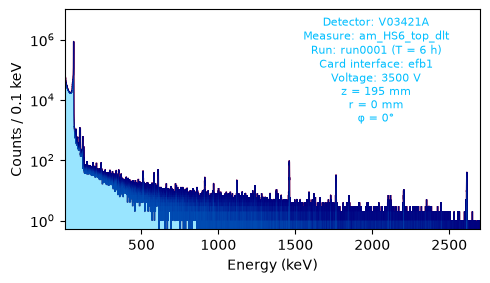

In [27]:
# ============================================================
# PLOT
# ============================================================
plt.figure(figsize=(5, 3))#, dpi = 300)


plt.stairs(
    counts_data,
    bins,
    color="red",
)
plt.stairs(
    counts_clean,
    bins,
    color="navy",
)
plt.stairs(
    counts_clean,
    bins,
    fill = True,
    alpha = 0.4,
    color="deepskyblue",
)

plt.annotate(
    annotation_measure,
    xy=(0.75, 0.97),
    xycoords="axes fraction",
    ha="center",
    va="top",
    multialignment="center",
    fontsize=8,
    zorder=8,
    color="deepskyblue",
)

# axvline non modifica i limiti verticali del grafico
#for energy in peaks.values():
#    plt.axvline(energy, color="red", linewidth=0.8)

#plt.axvline(2615, color="red", linewidth=0.8)

plt.yscale("log")
plt.ylim(0, 1e7)
plt.ylabel(f"Counts / {bins[1] - bins[0]:.1f} keV")
plt.xlabel("Energy (keV)")
plt.xlim(1, 2700)
plt.tight_layout()
plt.show()

In [28]:
print( Path("/global/u2/r/ritaferi/HADES_DATA")
    / "background_calibration_single_file"
    / version
    / campaign
    / detector)

/global/u2/r/ritaferi/HADES_DATA/background_calibration_single_file/v1.2.1/c1/V03421A


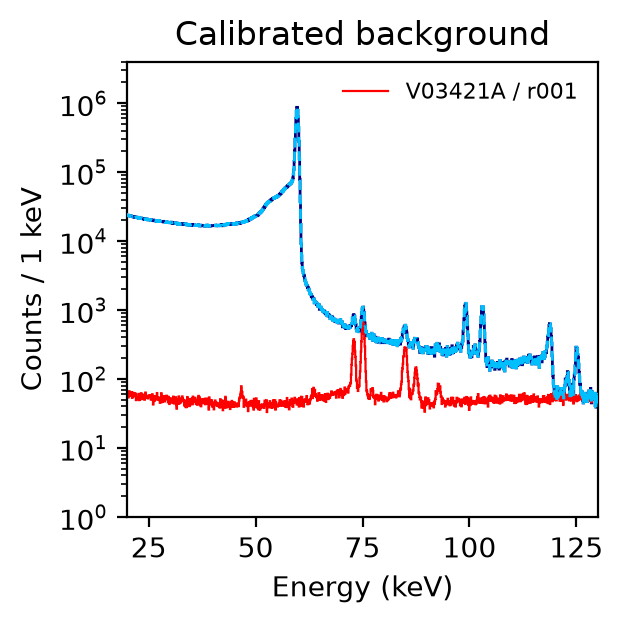

In [35]:

# ============================================================
# HISTOGRAM — 1 keV BINS
# ============================================================

#bins_bkg = np.linspace(0, 3500, 3501)

fig, ax = plt.subplots(
    figsize=(3,3),
    dpi=200,
    layout="constrained",
)

plt.stairs(
    counts_clean,
    bins,
    color="navy",
)
plt.stairs(
    counts_data,
    bins,
    color="deepskyblue",
    ls = '--',
    zorder = 10
)
ax.stairs(
    counts_bkg_scaled,
    bins,
    color="red",
    linewidth=0.8,
    label=f"{detector} / {run_tag}",
)



ax.set_yscale("log")
ax.set_ylim(bottom=0.5)
ax.set_xlim(20,130)
ax.set_ylim(1, 4e6)

ax.set_xlabel("Energy (keV)")
ax.set_ylabel("Counts / 1 keV")
ax.set_title("Calibrated background")
ax.legend(frameon=False, fontsize=8)

plt.show()

# counting method

In [38]:
pattern = (
    "/global/cfs/cdirs/m2676/data/teststands/hades/"
    "prodenv/ref/v1.2.1/generated/par/hit/"
    f"{detector}/c1/am_HS1_lat_dlt/*.yaml"
)

files_par = sorted(glob.glob(pattern))

if not files_par:
    raise FileNotFoundError(f"Nessun file trovato: {pattern}")

print(f"File trovati: {len(files_par)}")

# Carica tutti i YAML: una voce per ogni file.
parameters_by_file = {}

for filename in files_par:
    with open(filename, encoding="utf-8") as stream:
        parameters_by_file[filename] = yaml.safe_load(stream)

    print(filename)

File trovati: 1
/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/v1.2.1/generated/par/hit/V03421A/c1/am_HS1_lat_dlt/char_data-V03421A-am_HS1_lat_dlt-r001-20240324T201613Z-par_hit.yaml


In [39]:
par = parameters_by_file[files_par[0]]
print(par.keys())

dict_keys(['pars', 'results'])


In [40]:
def extract_sigma(E):
    a = par['results']['ecal']['cuspEmax_ctc_cal']["eres_quadratic"]["parameters"]["a"]

    b = par['results']['ecal']['cuspEmax_ctc_cal']["eres_quadratic"]["parameters"]["b"]
    
    c = par['results']['ecal']['cuspEmax_ctc_cal']["eres_quadratic"]["parameters"]["c"]
    
    return    (a+b*E+c*E**2)**(0.5)/2.355
    

In [41]:
bc = (bins[1:] + bins[:-1])*0.5


e_left_low , e_left_high = (56.5, 57.5)
mask_left = (bc >= e_left_low) & (bc <= e_left_high )
e_right_low, e_rigth_high = (61.5, 62.5)
mask_right = (bc >= e_right_low) & (bc <= e_rigth_high )

sigma = extract_sigma(59.5)
p1 = 59.5
peak_range = (p1 - 3 * sigma, p1 + 3 * sigma )
mask_peak = (bc >= peak_range[0]) & (bc <= peak_range[1])

In [42]:
count_left = np.sum(counts_clean[mask_left])
count_right = np.sum(counts_clean[mask_right])
counts_peak = np.sum(counts_clean[mask_peak])

In [43]:

sigma_peak = np.sum(np.sqrt(counts_clean[mask_peak]))
sigma_left = np.sum(np.sqrt(counts_clean[mask_left])) / ((e_left_high - e_left_high) + (e_rigth_high - e_right_low))
sigma_right = np.sum(np.sqrt(counts_clean[mask_right])) / ((e_left_high - e_left_high) + (e_rigth_high - e_right_low))

# uncorrelated ucertainties
sigma_tot = sigma_peak - (sigma_left + sigma_right)

print(sigma_tot)

6824.309973284675


In [44]:
counts_net = counts_peak - (count_left + count_right )/((e_left_high - e_left_high) + (e_rigth_high - e_right_low))

print('left tail count', count_left)
print('right tail count', count_right)
print('peak count', counts_peak)
print('net peak count', counts_net, '+/-', int(sigma_tot),',', int(counts_net/counts_peak *100), '%')

left tail count 588804
right tail count 22985
peak count 6740186
net peak count 6128397.0 +/- 6824 , 90 %


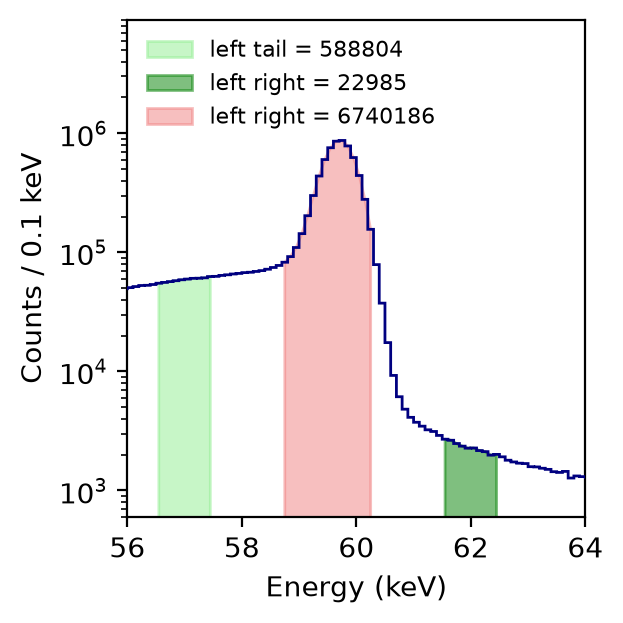

In [46]:

# ============================================================
# HISTOGRAM — 1 keV BINS
# ============================================================

#bins_bkg = np.linspace(0, 3500, 3501)


fig, ax = plt.subplots(
    figsize=(3,3),
    dpi=200,
    layout="constrained",
)

plt.stairs(
    counts_clean,
    bins,
    color="navy",
    zorder = 10
)

plt.fill_between(bc[mask_left] , counts_clean[mask_left] , color = 'lightgreen', alpha = 0.5,  label = f'left tail = {count_left} ')
plt.fill_between(bc[mask_right] , counts_clean[mask_right] , color = 'green',  alpha = 0.5, label = f'left right = {count_right} ')
plt.fill_between(bc[mask_peak] , counts_clean[mask_peak] , color = 'lightcoral', alpha = 0.5 , label = f'left right = {counts_peak} ')


ax.set_yscale("log")
ax.set_ylim(bottom=0.5)
ax.set_xlim(56,64)
ax.set_ylim(6e2, 9e6)

ax.set_xlabel("Energy (keV)")
ax.set_ylabel(f"Counts / {bins[1]-bins[0]:.1f} keV")
ax.legend(frameon=False, fontsize=8, loc = 'upper left')

plt.show()